# Lab 6: Land Use Classification from Satellite Images with a CNN

**Zhan Tabuldinov, BDA-2401**

In this lab I train a **Convolutional Neural Network (CNN)** that looks at a small satellite photo (64 × 64 pixels) and says what kind of land it shows: a field, a forest, a river, a highway, houses and so on. Instead of the usual CIFAR-10 or Fashion-MNIST I use the **EuroSAT** satellite dataset, because land-use monitoring is a real task for agriculture and city planning, including in Kazakhstan.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time, hashlib, collections
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
sns.set_theme(style="whitegrid")
tf.get_logger().setLevel("ERROR")
tf.random.set_seed(42); np.random.seed(42)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## 1. Dataset Selection

**Dataset:** EuroSAT (Dahiya, 2020), published on Kaggle, license CC0. The images were created by Helber et al. (2019) from photos of the European Sentinel-2 satellite.
**Link:** https://www.kaggle.com/datasets/apollo2506/eurosat-dataset

* **Images:** 27 000 colour (RGB) satellite photos; every image is 64 × 64 pixels and shows a piece of land 640 × 640 metres (10 metres per pixel).
* **Target classes (10):** AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake. From 2 000 to 3 000 images per class.
* **Why it is suitable for image classification:** every image has exactly one label, all images have the same size and format, the classes are visually different (colour, texture, shapes), and there are enough images for a CNN to learn. I use a random sample of **2 000 images per class (20 000 images)** so that the network trains in reasonable time on a laptop CPU.

In [2]:
import kagglehub
path = kagglehub.dataset_download("apollo2506/eurosat-dataset")
root = os.path.join(path, "EuroSAT")
classes = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
counts = {c: len(os.listdir(os.path.join(root, c))) for c in classes}
print("classes:", classes)
print("images per class:", counts, "| total:", sum(counts.values()))

classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
images per class: {'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000} | total: 27000


## 2. Business Understanding

* **Problem.** Governments and agro-companies need to know how land is used: how much is planted, where forests disappear, where new buildings or roads appear. Doing this by hand from satellite photos is impossible – one country produces millions of image tiles per year.
* **What the model predicts.** For every 64 × 64 tile – one of 10 land-use classes.
* **Who can use it.** The Ministry of Agriculture (area of crops and pastures, subsidies control), city planners (growth of residential and industrial zones), ecology services (forests and water), insurance and banks (checking that a field really exists).
* **Decisions supported.** Where to send an inspector, which fields to subsidise, where a road or a river changed, how the city grows year by year.

**Success criteria (on the test set):**

| Metric | Threshold | Reason |
|---|---|---|
| Accuracy | ≥ 0.85 | 10 classes, random guessing gives 0.10; 85 % is enough for automatic mapping with a manual check of the doubtful tiles |
| Macro F1 | ≥ 0.85 | every class matters equally (a rarer class like Pasture must not be ignored) |
| Recall of every class | ≥ 0.70 | no class should be "lost" |

**Short glossary** (definitions follow Géron, 2019, ch. 14). *CNN* – a neural network with convolutional layers, made for images. *Convolutional layer* – slides small filters (kernels) over the image and produces feature maps that show where a pattern (edge, colour, texture) is present. *Filter / kernel* – a small matrix of weights, for example 3 × 3. *Pooling layer* – reduces the size of a feature map by keeping the maximum of each small window. *Padding* – adding zeros around the image so that the output keeps the same size. *Stride* – the step of the filter. *Flatten* – turns the feature maps into one long vector for the dense layers. *Softmax* – output activation that gives a probability for each of the 10 classes. *Data augmentation* – creating new training images by flipping or rotating the existing ones. *Dropout* – randomly switches off some neurons during training to reduce over-fitting. The network is built with Keras / TensorFlow (Chollet, 2015; Abadi et al., 2016); metrics are computed with scikit-learn (Pedregosa et al., 2011).

## 3. Exploratory Data Analysis

In [3]:
N_PER_CLASS = 2000
rng = np.random.default_rng(42)
images, labels = [], []
for ci, c in enumerate(classes):
    for fn in rng.choice(sorted(os.listdir(os.path.join(root, c))), N_PER_CLASS, replace=False):
        images.append(np.asarray(Image.open(os.path.join(root, c, fn)).convert("RGB"), dtype=np.uint8)); labels.append(ci)
X = np.stack(images); y = np.array(labels); del images
print("sample shape:", X.shape, "| dtype:", X.dtype, "| pixel range:", X.min(), "-", X.max(), "| memory: %.0f MB" % (X.nbytes / 1e6))

sample shape: (20000, 64, 64, 3) | dtype: uint8 | pixel range: 0 - 255 | memory: 246 MB


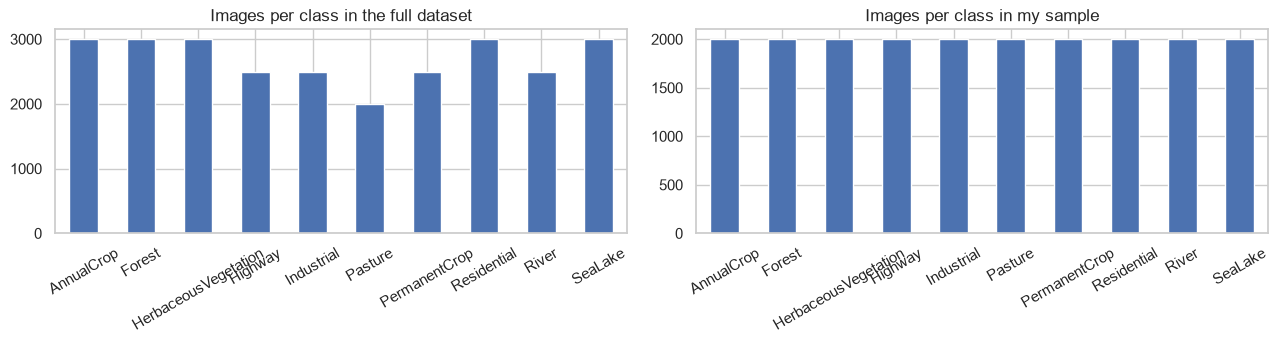

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
pd.Series(counts).plot.bar(ax=ax[0], color="#4C72B0", rot=30, title="Images per class in the full dataset")
pd.Series(np.bincount(y), index=classes).plot.bar(ax=ax[1], color="#4C72B0", rot=30, title="Images per class in my sample")
plt.tight_layout(); plt.show()

**Figure 1.** The full dataset is a little imbalanced (Pasture 2 000, the biggest classes 3 000 images). My sample takes exactly the same number of images from each class, so the 10 classes are perfectly balanced and accuracy is a fair metric.

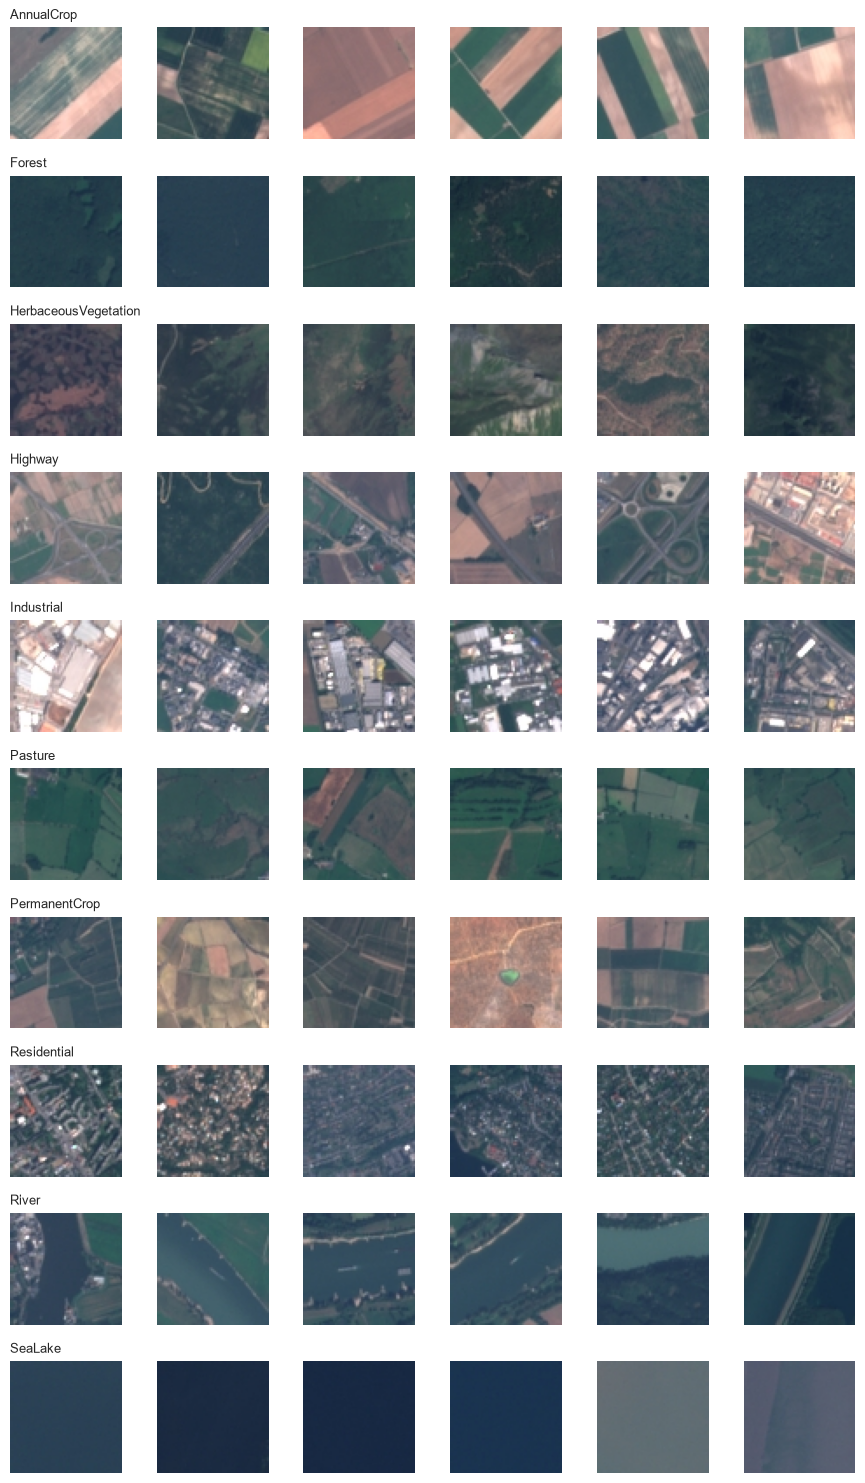

In [5]:
fig, ax = plt.subplots(10, 6, figsize=(9, 15))
for ci, c in enumerate(classes):
    for j, i in enumerate(np.where(y == ci)[0][:6]):
        ax[ci, j].imshow(X[i]); ax[ci, j].axis("off")
    ax[ci, 0].set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

**Figure 2.** Six random images of every class. The classes differ by colour and texture: Forest is dark green and smooth, SeaLake is blue or almost black, AnnualCrop and Pasture are light green or brown fields, Residential and Industrial have many small rectangles (buildings), Highway and River are long lines crossing the tile. Some pairs look similar – AnnualCrop vs PermanentCrop, HerbaceousVegetation vs Pasture, Highway vs River – these will be the hard cases for the model.

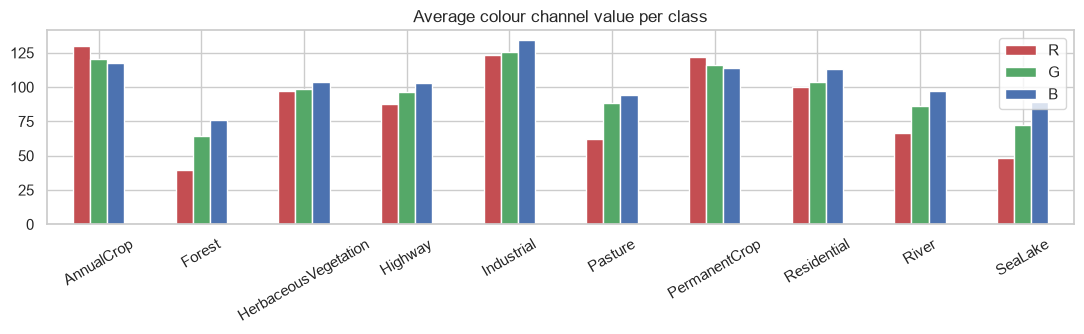

,R,G,B
AnnualCrop,129.9,120.2,117.4
Forest,39.4,64.5,75.9
HerbaceousVegetation,97.5,98.3,103.4
Highway,87.4,96.3,103.1
Industrial,123.7,125.7,134.5
Pasture,61.9,88.5,94.2
PermanentCrop,122.0,116.0,114.0
Residential,100.1,103.8,113.0
River,66.8,86.5,97.0
SeaLake,48.0,72.6,89.0


In [6]:
mean_rgb = pd.DataFrame([X[y == ci].reshape(-1, 3).mean(axis=0) for ci in range(len(classes))], index=classes, columns=["R", "G", "B"])
mean_rgb.plot.bar(figsize=(11, 3.5), color=["#C44E52", "#55A868", "#4C72B0"], rot=30, title="Average colour channel value per class")
plt.tight_layout(); plt.show()
mean_rgb.round(1)

**Figure 3.** The average colour already separates some classes: SeaLake has a low red value and high blue, Forest is the darkest class, Industrial and AnnualCrop are the brightest (concrete, roofs, bare soil). But several classes have almost the same average colour (HerbaceousVegetation, Highway, Residential), so colour alone is not enough – the network must learn shapes and textures. That is exactly what convolutional filters do.

## 4. Data Cleaning

In [7]:
sizes, modes, corrupt, wrong_ext, wrong_name = collections.Counter(), collections.Counter(), 0, 0, 0
for c in classes:
    for fn in os.listdir(os.path.join(root, c)):
        wrong_ext += not fn.lower().endswith(".jpg"); wrong_name += not fn.startswith(c)
        try:
            im = Image.open(os.path.join(root, c, fn)); sizes[im.size] += 1; modes[im.mode] += 1
        except Exception:
            corrupt += 1
print("image sizes in the full dataset:", dict(sizes), "| colour modes:", dict(modes))
print("unreadable (corrupted) files:", corrupt, "| wrong extension:", wrong_ext, "| file name does not match class folder:", wrong_name)

image sizes in the full dataset: {(64, 64): 27000} | colour modes: {'RGB': 27000}
unreadable (corrupted) files: 0 | wrong extension: 0 | file name does not match class folder: 0


In [8]:
hashes = collections.defaultdict(list)
for i in range(len(X)):
    hashes[hashlib.md5(X[i].tobytes()).hexdigest()].append(i)
n_dup = sum(len(v) - 1 for v in hashes.values() if len(v) > 1)
n_flat = int((X.reshape(len(X), -1).std(axis=1) < 1).sum())
print("exact duplicate images in the sample:", n_dup)
print("images that are completely one colour (empty tiles):", n_flat)
keep = np.ones(len(X), bool)
for v in hashes.values():
    for i in v[1:]: keep[i] = False
keep &= X.reshape(len(X), -1).std(axis=1) >= 1
print("shape before cleaning:", X.shape, "-> after:", X[keep].shape)
X, y = X[keep], y[keep]

exact duplicate images in the sample: 0
images that are completely one colour (empty tiles): 0


shape before cleaning: (20000, 64, 64, 3) -> after: (20000, 64, 64, 3)


**Result of the checks.** The RGB part of EuroSAT is clean: all 27 000 files open, all are 64 × 64 RGB JPEG, every file name starts with the name of its class folder (so there are no visible label mistakes), and in the sample there are no exact duplicates and no empty one-colour tiles. The cleaning code is still applied (it would drop duplicates and empty tiles if they existed), but nothing is removed – the sample keeps its shape.

One real problem exists in the *other* part of the Kaggle upload: the folder `EuroSATallBands/SeaLake` contains about 600 extra `.tif` files named `Bombay_*` that do not belong to EuroSAT. I do not use the all-bands folder, so these files do not affect the work, but it is a good example of why a dataset must be checked before training.

## 5. Feature Engineering

For images the "features" are the pixels themselves; the CNN learns the useful patterns (edges, textures, colours) on its own. What I decide here:

* **Useful information kept:** all three colour channels (RGB) – colour separates water, forest and fields (Figure 3) – and the full 64 × 64 resolution, because roads, rivers and buildings are only a few pixels wide and would disappear after downscaling.
* **Irrelevant information avoided:** file names and the order of files (they carry the label and could leak it); the 13-band `.tif` version of the data (too heavy for a laptop and not needed for these 10 classes).
* **Resizing:** not needed – all images are already 64 × 64.
* **Data augmentation:** a satellite tile does not have a "correct" orientation – a field flipped left-right or rotated is still a field. So random horizontal / vertical flips and small rotations (± 10 % of a turn) are added as the first layers of the improved models. This creates "new" training images every epoch and helps the network not to memorise the training tiles.

## 6. Data Preprocessing

* **Split:** 80 % / 20 % train / test (stratified, `random_state=42`), then 20 % of the training part becomes the validation set. The test set is used only once, in Section 8.
* **Normalisation:** pixel values 0–255 are divided by 255 inside the model (`Rescaling` layer), so inputs are in 0–1; the images stay in memory as small `uint8` arrays.
* **Labels:** classes are encoded as integers 0–9 (`sparse_categorical_crossentropy` works with them directly, no one-hot needed).
* **No leakage:** the split is done before any training, the augmentation layers work only during training, and the scaling constant 1/255 does not depend on the data.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
print("train:", X_train.shape, "| validation:", X_val.shape, "| test:", X_test.shape)
print("images per class in train:", np.bincount(y_train).tolist())

train: (12800, 64, 64, 3) | validation: (3200, 64, 64, 3) | test: (4000, 64, 64, 3)
images per class in train: [1280, 1280, 1280, 1280, 1280, 1280, 1280, 1280, 1280, 1280]


## 7. CNN Training

**How the image goes through the network (baseline model A).**

| Layer | Output size | What it does |
|---|---|---|
| Input | 64 × 64 × 3 | the RGB image, scaled to 0–1 |
| Conv2D, 32 filters 3 × 3, ReLU, padding "same", stride 1 | 64 × 64 × 32 | 32 small filters slide over the image one pixel at a time; each produces a map that lights up where its pattern (an edge, a colour change) appears |
| MaxPooling 2 × 2 | 32 × 32 × 32 | keeps the strongest value of every 2 × 2 window – the map becomes 4 times smaller, the patterns stay |
| Conv2D, 64 filters 3 × 3, ReLU | 32 × 32 × 64 | combines simple patterns into more complex ones (corners, textures of roofs or trees) |
| MaxPooling 2 × 2 | 16 × 16 × 64 | again halves the size |
| Flatten | 16 384 | the feature maps become one long vector |
| Dense 64, ReLU | 64 | learns which combinations of patterns mean which class |
| Dense 10, Softmax | 10 | probability of each land-use class |

Padding "same" keeps the width and height after a convolution, so only pooling makes the image smaller. Loss: sparse categorical cross-entropy; optimizer: Adam (Kingma & Ba, 2015).

In [10]:
def build(blocks=(32, 64), kernel=3, lr=0.001, dropout=0.0, augment=False):
    layers = [keras.Input(shape=X.shape[1:]), keras.layers.Rescaling(1 / 255)]
    if augment:
        layers += [keras.layers.RandomFlip("horizontal_and_vertical"), keras.layers.RandomRotation(0.1)]
    for f in blocks:
        layers += [keras.layers.Conv2D(f, kernel, padding="same", activation="relu"), keras.layers.MaxPooling2D(2)]
    layers += [keras.layers.Flatten(), keras.layers.Dense(64, activation="relu")]
    if dropout: layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(len(classes), activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

results = {}
def train_and_score(name, epochs=10, batch_size=64, **kw):
    model = build(**kw); t = time.time()
    h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, verbose=0)
    p = model.predict(X_test, verbose=0).argmax(axis=1)
    results[name] = {"params": model.count_params(), "test accuracy": accuracy_score(y_test, p), "macro F1": f1_score(y_test, p, average="macro"),
                     "train acc (last)": h.history["accuracy"][-1], "val acc (best)": max(h.history["val_accuracy"]), "epochs": epochs, "time, s": time.time() - t}
    print("%s -> test accuracy %.3f, macro F1 %.3f, %.0f s" % (name, results[name]["test accuracy"], results[name]["macro F1"], results[name]["time, s"]))
    return model, h, p

build().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,068,682 (4.08 MB)

 Trainable params: 1,068,682 (4.08 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Experiments with the architecture and hyperparameters

Each configuration is trained for 10 epochs with batch size 64 and scored on the test set. Only one thing changes between neighbouring rows, so the effect of every parameter is visible.

In [11]:
_ = train_and_score("A: 2 conv blocks (32, 64), 3x3", epochs=10)
_ = train_and_score("B: 3 conv blocks (32, 64, 128), 3x3", epochs=10, blocks=(32, 64, 128))
_ = train_and_score("C: 3 conv blocks, 5x5 kernels", epochs=10, blocks=(32, 64, 128), kernel=5)
_ = train_and_score("D: 3 conv blocks, learning rate 0.01", epochs=10, blocks=(32, 64, 128), lr=0.01)
_ = train_and_score("E: 3 conv blocks + dropout 0.3 + augmentation", epochs=10, blocks=(32, 64, 128), dropout=0.3, augment=True)
pd.DataFrame(results).T.round(3)

A: 2 conv blocks (32, 64), 3x3 -> test accuracy 0.775, macro F1 0.774, 160 s


B: 3 conv blocks (32, 64, 128), 3x3 -> test accuracy 0.793, macro F1 0.791, 186 s


C: 3 conv blocks, 5x5 kernels -> test accuracy 0.756, macro F1 0.754, 1041 s


D: 3 conv blocks, learning rate 0.01 -> test accuracy 0.683, macro F1 0.684, 203 s


E: 3 conv blocks + dropout 0.3 + augmentation -> test accuracy 0.812, macro F1 0.811, 250 s


,params,test accuracy,macro F1,train acc (last),val acc (best),epochs,"time, s"
"A: 2 conv blocks (32, 64), 3x3",1068682.0,0.775,0.774,0.871,0.781,10.0,160.137
"B: 3 conv blocks (32, 64, 128), 3x3",618250.0,0.793,0.791,0.841,0.800,10.0,185.509
"C: 3 conv blocks, 5x5 kernels",783626.0,0.756,0.754,0.821,0.793,10.0,1040.986
"D: 3 conv blocks, learning rate 0.01",618250.0,0.683,0.684,0.737,0.692,10.0,202.839
E: 3 conv blocks + dropout 0.3 + augmentation,618250.0,0.812,0.811,0.737,0.798,10.0,250.057


**What the experiments show** (10 epochs each, test set of 4 000 images).

* **Depth (A vs B).** Adding a third convolutional block with 128 filters raises test accuracy from 0.775 to 0.793 and, interestingly, *reduces* the number of parameters (1.07 M → 0.62 M): the extra pooling makes the flattened vector 4 times shorter, so the dense layer is smaller. Deeper is better here because land-use classes need patterns of patterns (texture of a roof, not just an edge).
* **Kernel size (B vs C).** 5 × 5 kernels are worse (0.756) and about 5 times slower (1 041 s against 186 s). Small 3 × 3 kernels are enough for 64 × 64 tiles; big kernels only add parameters and smooth away small details such as roads.
* **Learning rate (B vs D).** A learning rate of 0.01 instead of 0.001 drops accuracy to 0.683: the steps are too large, the loss jumps around and the network does not settle. The default 0.001 for Adam is the right choice.
* **Dropout + augmentation (B vs E).** Configuration E is the best of the five (0.812). Look at the train accuracy column: without regularisation the models reach 0.82–0.87 on the training set but only 0.76–0.79 on the test set (a gap of 5–9 points = over-fitting). With dropout and augmentation the train accuracy is lower (0.737) but the test accuracy is *higher* – the network stops memorising the training tiles and learns more general patterns. This configuration also keeps improving after 10 epochs, so it is trained longer in 7.2.

### 7.2 Final model

Configuration E (3 convolutional blocks with 32 / 64 / 128 filters, dropout 0.3, data augmentation) trained for 30 epochs. Augmentation makes every epoch different, so a longer training helps this model more than the others.

In [12]:
final, hist, pred = train_and_score("F: E trained for 30 epochs", epochs=30, blocks=(32, 64, 128), dropout=0.3, augment=True)
pd.DataFrame(results).T.round(3)

F: E trained for 30 epochs -> test accuracy 0.857, macro F1 0.855, 688 s


,params,test accuracy,macro F1,train acc (last),val acc (best),epochs,"time, s"
"A: 2 conv blocks (32, 64), 3x3",1068682.0,0.775,0.774,0.871,0.781,10.0,160.137
"B: 3 conv blocks (32, 64, 128), 3x3",618250.0,0.793,0.791,0.841,0.800,10.0,185.509
"C: 3 conv blocks, 5x5 kernels",783626.0,0.756,0.754,0.821,0.793,10.0,1040.986
"D: 3 conv blocks, learning rate 0.01",618250.0,0.683,0.684,0.737,0.692,10.0,202.839
E: 3 conv blocks + dropout 0.3 + augmentation,618250.0,0.812,0.811,0.737,0.798,10.0,250.057
F: E trained for 30 epochs,618250.0,0.857,0.855,0.835,0.863,30.0,688.206


### 7.3 Technical questions

**1. Convolutional layer vs pooling layer.** A convolutional layer has *trainable* filters: it multiplies every small window of the image by the filter weights and produces a new feature map – it *detects patterns*. A pooling layer has *no weights*: it only makes the feature map smaller by taking the maximum (or average) of every window – it *reduces size* and makes the detection less sensitive to the exact position of a pattern.

**2. Trainable parameters of a Conv2D layer with 32 filters, 3 × 3 kernel, 3 input channels.** Every filter has 3 × 3 × 3 = 27 weights plus 1 bias = 28 parameters. For 32 filters: 32 × 28 = **896 parameters** (the model summary above shows exactly 896 for the first convolutional layer).

**3. Padding and stride.** *Padding* adds a border of zeros around the image so that the filter can also be centred on the edge pixels; with padding "same" the output has the same height and width as the input, without padding a 3 × 3 filter makes the image 2 pixels smaller. *Stride* is the step of the filter: stride 1 looks at every position, stride 2 skips every second position and makes the output twice smaller (a cheap alternative to pooling).

**4. ReLU of [−5, −2, 0, 3, 7].** ReLU(x) = max(0, x), so the output is **[0, 0, 0, 3, 7]**.

**5. Size of 10 000 RGB images of 224 × 224 pixels, 8 bits per channel.** One image = 224 × 224 × 3 bytes = 150 528 bytes ≈ 0.15 MB. 10 000 images = 1 505 280 000 bytes ≈ **1 505 MB ≈ 1.5 GB** (1 436 MiB ≈ 1.4 GiB if 1 MB = 1 024 × 1 024 bytes).

In [13]:
print("check of question 2 in code:", keras.layers.Conv2D(32, 3, input_shape=(64, 64, 3)).__class__.__name__, "->", build().layers[1].count_params(), "parameters")
print("check of question 4 in code:", tf.nn.relu(tf.constant([-5., -2., 0., 3., 7.])).numpy())
print("check of question 5 in code: %.0f MB = %.2f GB" % (10000 * 224 * 224 * 3 / 1e6, 10000 * 224 * 224 * 3 / 1e9))

check of question 2 in code: Conv2D -> 896 parameters
check of question 4 in code: [0. 0. 0. 3. 7.]
check of question 5 in code: 1505 MB = 1.51 GB


## 8. Evaluation

In [14]:
print("accuracy  = %.4f" % accuracy_score(y_test, pred))
print("precision = %.4f (macro)" % precision_score(y_test, pred, average="macro"))
print("recall    = %.4f (macro)" % recall_score(y_test, pred, average="macro"))
print("F1        = %.4f (macro)" % f1_score(y_test, pred, average="macro"))
report = pd.DataFrame(classification_report(y_test, pred, target_names=classes, output_dict=True)).T.round(3).iloc[:len(classes)]
report["meets recall >= 0.70"] = report["recall"] >= 0.70
print("best class: %s (F1 %.3f) | worst class: %s (F1 %.3f)" % (report["f1-score"].idxmax(), report["f1-score"].max(), report["f1-score"].idxmin(), report["f1-score"].min()))
report

accuracy  = 0.8568
precision = 0.8609 (macro)
recall    = 0.8568 (macro)
F1        = 0.8549 (macro)


best class: SeaLake (F1 0.970) | worst class: Highway (F1 0.689)


,precision,recall,f1-score,support,meets recall >= 0.70
AnnualCrop,0.939,0.842,0.888,400.0,True
Forest,0.973,0.908,0.939,400.0,True
HerbaceousVegetation,0.715,0.870,0.785,400.0,True
Highway,0.813,0.598,0.689,400.0,False
Industrial,0.871,0.948,0.908,400.0,True
Pasture,0.851,0.870,0.860,400.0,True
PermanentCrop,0.818,0.740,0.777,400.0,True
Residential,0.820,0.982,0.894,400.0,True
River,0.828,0.852,0.840,400.0,True
SeaLake,0.982,0.958,0.970,400.0,True


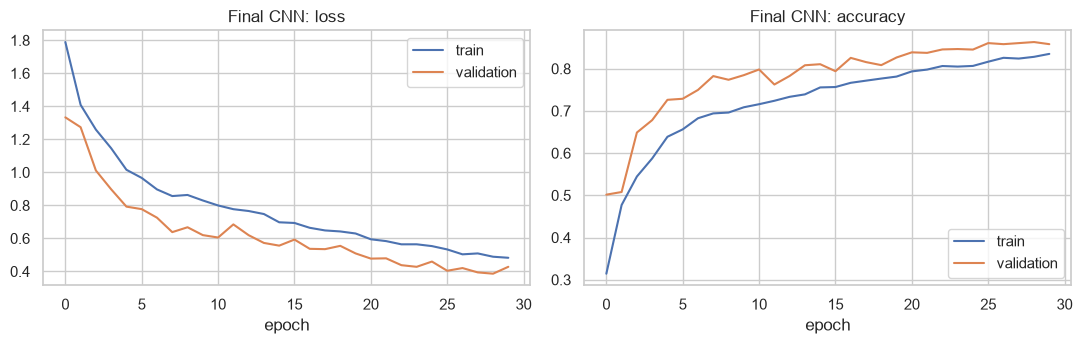

last epoch: train acc 0.835, val acc 0.858 | train loss 0.483, val loss 0.428


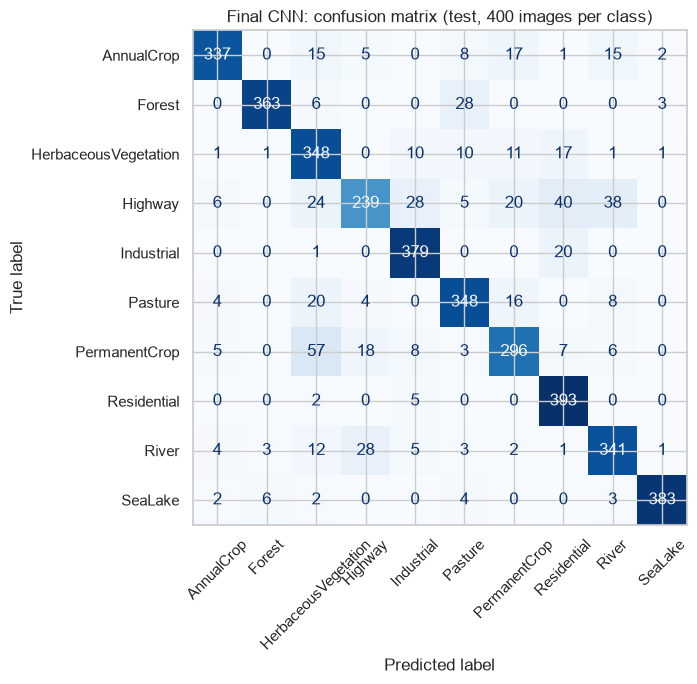

most frequent confusions: ['PermanentCrop -> HerbaceousVegetation (57)', 'Highway -> Residential (40)', 'Highway -> River (38)']


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="validation"); ax[0].set(title="Final CNN: loss", xlabel="epoch"); ax[0].legend()
ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="validation"); ax[1].set(title="Final CNN: accuracy", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()
print("last epoch: train acc %.3f, val acc %.3f | train loss %.3f, val loss %.3f" % (hist.history["accuracy"][-1], hist.history["val_accuracy"][-1], hist.history["loss"][-1], hist.history["val_loss"][-1]))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Final CNN: confusion matrix (test, %d images per class)" % np.bincount(y_test)[0]); plt.tight_layout(); plt.show()
cm = confusion_matrix(y_test, pred); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:3], cm.shape))[0]
print("most frequent confusions:", ["%s -> %s (%d)" % (classes[a], classes[b], cm[a, b]) for a, b in top])

**Final metrics (test, 4 000 images).** Accuracy 0.857, macro precision 0.861, macro recall 0.857, macro F1 0.855 – an improvement from 0.812 (10 epochs) to 0.857 (30 epochs) for the same configuration E, so the longer training was worth it.

**Under-fitting or over-fitting?** The curves answer this clearly. Both losses fall together for all 30 epochs, and the validation line is *below* the training line (train loss 0.483 vs validation loss 0.428; train accuracy 0.835 vs validation 0.858). This is normal for a model with dropout and augmentation: during training the network sees harder, modified images with part of the neurons switched off, while validation uses clean images and the full network. There is no over-fitting at all. If anything, the model is still slightly **under-fitted** – the validation accuracy is still growing in the last epochs, so more epochs or a wider network would give a few more points.

**Which classes are easy and which are hard.** SeaLake (F1 0.970), Forest (0.939), Industrial (0.908), Residential (0.894) and AnnualCrop (0.888) are recognised very well – they have a unique colour or a dense, regular texture. The hard classes are **Highway (F1 0.689, recall 0.598)**, PermanentCrop (0.777) and HerbaceousVegetation (0.785). The confusion matrix shows why: a highway is a thin line on a background that looks like a residential or river tile, so 40 highways were called Residential and 38 were called River; 57 PermanentCrop tiles (orchards, vineyards) were called HerbaceousVegetation, because at 10 m per pixel both are just "green with some structure". These are the same pairs that already looked similar in Figure 2.

**Business criteria.** Accuracy 0.857 ≥ 0.85 – met. Macro F1 0.855 ≥ 0.85 – met. Recall ≥ 0.70 for every class – **not met for Highway** (0.598); the other nine classes pass. So two of the three criteria are achieved, and the model is usable for automatic mapping of the nine "easy" classes, while Highway tiles should be sent to manual check.

## 9. Conclusion

* **Data.** EuroSAT satellite tiles (Kaggle), 10 land-use classes, 64 × 64 RGB. A balanced sample of 2 000 images per class (20 000 images) was checked for corrupted files, wrong sizes, label / folder mismatches, exact duplicates and empty tiles – nothing had to be removed. Split 12 800 / 3 200 / 4 000 (train / validation / test), pixels scaled to 0–1 inside the model, labels as integers.
* **Final CNN.** Input 64 × 64 × 3 → [Conv 32 (3 × 3, ReLU, padding same) → MaxPool 2 × 2] → [Conv 64 → MaxPool] → [Conv 128 → MaxPool] → Flatten → Dense 64 (ReLU) → Dropout 0.3 → Dense 10 (Softmax), with random flips and rotations as augmentation; 618 250 parameters; Adam, learning rate 0.001, batch 64, 30 epochs.
* **Best configuration and why.** Three convolutional blocks beat two (more complex patterns), 3 × 3 kernels beat 5 × 5 (small details matter, 5 times faster), learning rate 0.001 beats 0.01 (stable training), and dropout + augmentation give the biggest single gain because they stop the network from memorising the training tiles. Training the regularised model for 30 instead of 10 epochs adds another 4.5 points.
* **Performance.** Test accuracy 0.857, macro F1 0.855; no over-fitting (validation above training). Two of three success criteria are met; the recall criterion fails only for Highway (0.598), which is confused with Residential and River tiles.
* **Improvements.** (1) *Transfer learning* – a network pre-trained on ImageNet (for example MobileNetV2 or ResNet50) fine-tuned on EuroSAT reaches about 95–98 % in the literature (Helber et al., 2019), because its filters already know edges, textures and shapes. (2) *Batch normalization and a deeper network* (4–5 blocks, 256 filters) with more epochs, since the current model is still under-fitted. (3) *More data and multispectral bands* – the full 27 000 images instead of 20 000, and the near-infrared band from the 13-band version, which separates vegetation types (crop vs grass) much better than RGB.

## 10. References

Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., Devin, M., Ghemawat, S., Irving, G., Isard, M., Kudlur, M., Levenberg, J., Monga, R., Moore, S., Murray, D. G., Steiner, B., Tucker, P., Vasudevan, V., Warden, P., … Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. *Proceedings of the 12th USENIX Symposium on Operating Systems Design and Implementation (OSDI 16)*, 265–283.

Chollet, F. (2015). *Keras* [Computer software]. https://keras.io

Dahiya, G. (2020). *EuroSAT dataset* [Data set]. Kaggle. https://www.kaggle.com/datasets/apollo2506/eurosat-dataset

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow: Concepts, tools, and techniques to build intelligent systems* (2nd ed.). O'Reilly Media. (Chapter 14: deep computer vision using convolutional neural networks)

Helber, P., Bischke, B., Dengel, A., & Borth, D. (2019). EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 12*(7), 2217–2226. https://doi.org/10.1109/JSTARS.2019.2918242

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1412.6980

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.